<a href="https://colab.research.google.com/github/Subhana729/PROJECT/blob/main/lab_07_dl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

========== ZERO PADDING TEST ==========
Original shape: (2, 4, 4, 3)
Padded shape: (2, 8, 8, 3)
Top border zero: True
Bottom border zero: True
Left border zero: True
Right border zero: True
Padding verification: True

========== IMAGE INFORMATION ==========
Image shape: (512, 512)
Image data type: float64


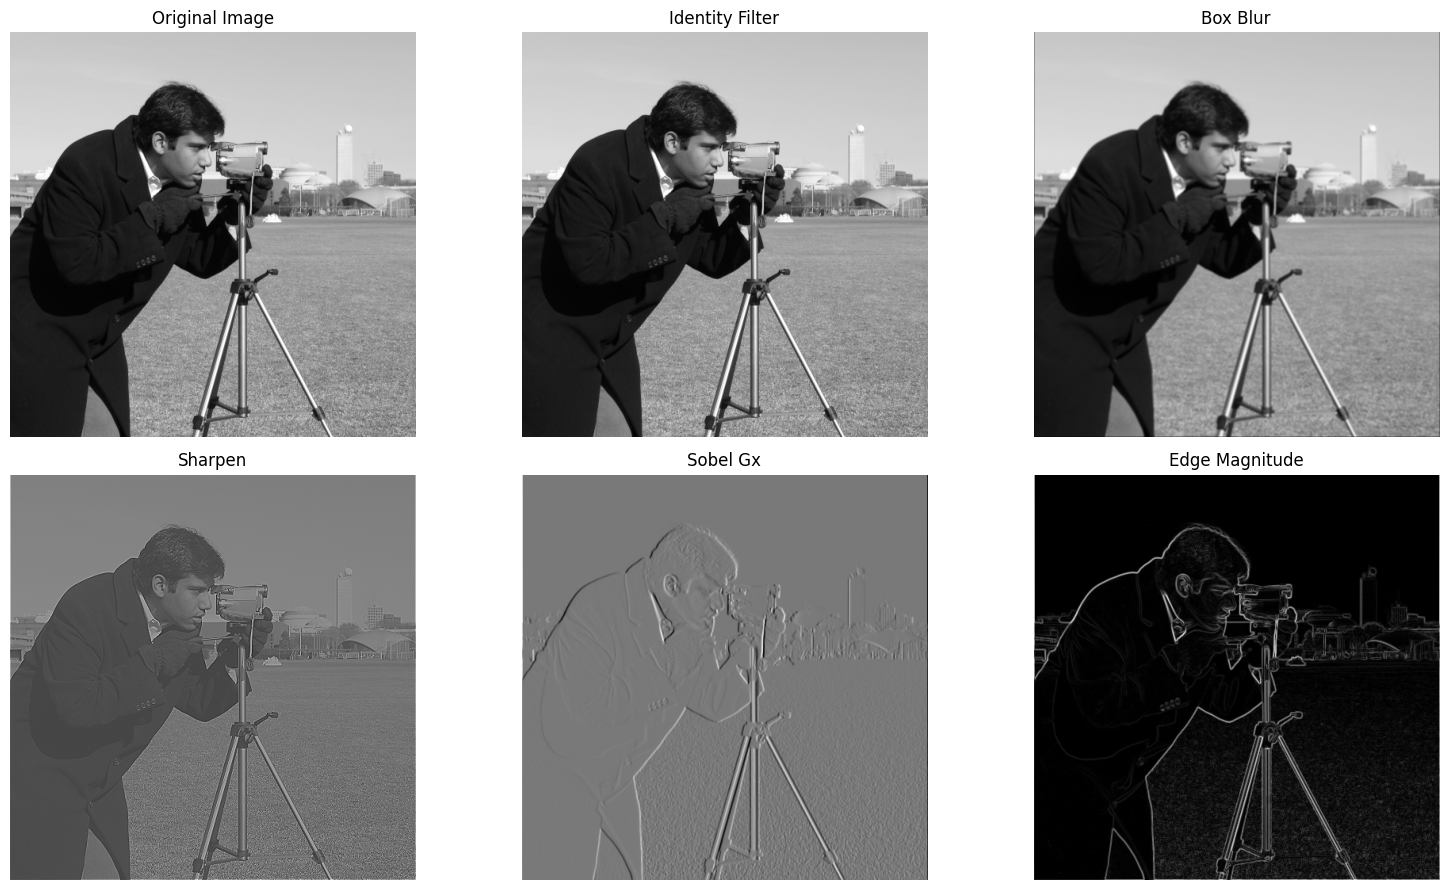

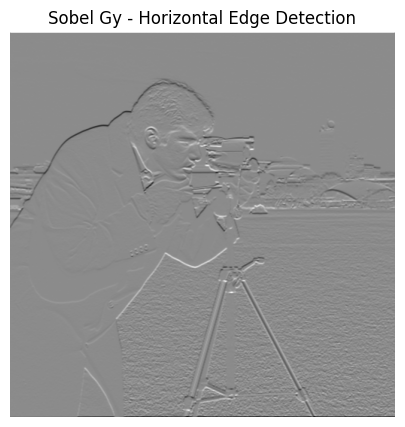


========== NUMPY CONVOLUTION ==========
Input shape: (1, 12, 12, 1)
Filter shape: (3, 3, 1, 1)
Output shape: (1, 12, 12, 1)
NumPy execution time: 0.0022475730002042837 seconds

========== FULL IMAGE TIME ESTIMATION ==========
Crop size: 12 x 12
Full image size: 512 x 512
Estimated full image time: 4.09158178170522 seconds
Estimated full image time: 0.068193029695087 minutes

========== PYTORCH VERIFICATION ==========
NumPy output shape: (1, 12, 12, 1)
PyTorch output shape: (1, 12, 12, 1)
Relative difference: 0.0
VERIFICATION SUCCESSFUL

========== SPEED COMPARISON ==========
NumPy loop time: 0.0022475730002042837 seconds
PyTorch average time: 4.515930999787088e-05 seconds
PyTorch speed factor: 49.769870272824136 x

========== SOBEL FILTER RESULTS ==========
Sobel Gx detects vertical edges.
Sobel Gy detects horizontal edges.
Edge magnitude combines both directions.
Formula: sqrt(Gx^2 + Gy^2)
It represents the overall strength of edges.


In [5]:

# ================================================================
# DEEP LEARNING LAB 07
# TASK 1: CONVOLUTION FROM SCRATCH
# ================================================================

# -------------------- IMPORT LIBRARIES ---------------------------

import numpy as np
import matplotlib.pyplot as plt
import time

from skimage import data

import torch
import torch.nn.functional as F


# ================================================================
# PART 1: ZERO PADDING FUNCTION
# ================================================================

def zero_pad(X, p):
    """
    X shape: (m, n_H, n_W, n_C)
    Pad height and width only.
    """

    X_pad = np.pad(
        X,
        ((0, 0), (p, p), (p, p), (0, 0)),
        mode='constant',
        constant_values=0
    )

    return X_pad


# -------------------- TEST ZERO PADDING --------------------------

np.random.seed(1)

X = np.random.randn(2, 4, 4, 3)

X_pad = zero_pad(X, 2)

print("========== ZERO PADDING TEST ==========")

print("Original shape:", X.shape)
print("Padded shape:", X_pad.shape)

print("Top border zero:",
      np.all(X_pad[:, 0, :, :] == 0))

print("Bottom border zero:",
      np.all(X_pad[:, -1, :, :] == 0))

print("Left border zero:",
      np.all(X_pad[:, :, 0, :] == 0))

print("Right border zero:",
      np.all(X_pad[:, :, -1, :] == 0))

print("Padding verification:",
      X_pad.shape == (2, 8, 8, 3))


# ================================================================
# PART 2: CONVOLUTION SINGLE STEP FUNCTION
# ================================================================

def conv_single_step(a_slice, W, b):
    """
    Performs convolution on one input patch.
    """

    s = np.multiply(a_slice, W)

    Z = np.sum(s) + float(np.squeeze(b))

    return Z


# ================================================================
# PART 3: FORWARD CONVOLUTION FUNCTION
# ================================================================

def conv_forward(A_prev, W, b, stride=1, pad=0):

    # Input dimensions
    m, n_H, n_W, n_C = A_prev.shape

    # Filter dimensions
    f, _, n_C_prev, n_C_out = W.shape

    # Check channel compatibility
    assert n_C == n_C_prev

    # Check valid parameters
    assert stride > 0 and pad >= 0

    # Output dimensions
    out_H = int((n_H + 2 * pad - f) / stride) + 1

    out_W = int((n_W + 2 * pad - f) / stride) + 1

    # Initialize output
    Z = np.zeros(
        (m, out_H, out_W, n_C_out),
        dtype=np.result_type(A_prev, W, b, np.float64)
    )

    # Apply zero padding
    Ap = zero_pad(A_prev, pad)

    # Perform convolution
    for i in range(m):

        for h in range(out_H):

            for w in range(out_W):

                for c in range(n_C_out):

                    # Find patch boundaries
                    vert_start = h * stride
                    vert_end = vert_start + f

                    horiz_start = w * stride
                    horiz_end = horiz_start + f

                    # Extract patch
                    a_slice = Ap[
                        i,
                        vert_start:vert_end,
                        horiz_start:horiz_end,
                        :
                    ]

                    # Calculate output value
                    Z[i, h, w, c] = conv_single_step(
                        a_slice,
                        W[:, :, :, c],
                        b[:, :, :, c]
                    )

    # Store cache
    cache = (A_prev, W, b, stride, pad)

    return Z, cache


# ================================================================
# PART 4: CREATE FIVE 3x3 FILTERS
# ================================================================

identity = np.array([
    [0, 0, 0],
    [0, 1, 0],
    [0, 0, 0]
], dtype=float)


box_blur = np.ones((3, 3), dtype=float) / 9


sharpen = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=float)


sobel_Gx = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=float)


sobel_Gy = np.array([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1]
], dtype=float)


# ================================================================
# PART 5: LOAD SAMPLE PHOTOGRAPH
# ================================================================

image = data.camera().astype(np.float64)

print("\n========== IMAGE INFORMATION ==========")

print("Image shape:", image.shape)

print("Image data type:", image.dtype)


# ================================================================
# PART 6: APPLY FIVE FILTERS
# ================================================================

# Identity filter
identity_result = F.conv2d(
    torch.tensor(image).reshape(1, 1, 512, 512),
    torch.tensor(identity).reshape(1, 1, 3, 3),
    padding=1
).numpy()[0, 0]


# Box blur
blur_result = F.conv2d(
    torch.tensor(image).reshape(1, 1, 512, 512),
    torch.tensor(box_blur).reshape(1, 1, 3, 3),
    padding=1
).numpy()[0, 0]


# Sharpen filter
sharpen_result = F.conv2d(
    torch.tensor(image).reshape(1, 1, 512, 512),
    torch.tensor(sharpen).reshape(1, 1, 3, 3),
    padding=1
).numpy()[0, 0]


# Sobel Gx
Gx = F.conv2d(
    torch.tensor(image).reshape(1, 1, 512, 512),
    torch.tensor(sobel_Gx).reshape(1, 1, 3, 3),
    padding=1
).numpy()[0, 0]


# Sobel Gy
Gy = F.conv2d(
    torch.tensor(image).reshape(1, 1, 512, 512),
    torch.tensor(sobel_Gy).reshape(1, 1, 3, 3),
    padding=1
).numpy()[0, 0]


# ================================================================
# PART 7: EDGE MAGNITUDE
# ================================================================

edge_magnitude = np.sqrt(Gx**2 + Gy**2)


# ================================================================
# PART 8: DISPLAY SIX PANELS SIDE BY SIDE
# ================================================================

plt.figure(figsize=(16, 9))

images = [
    image,
    identity_result,
    blur_result,
    sharpen_result,
    Gx,
    edge_magnitude
]

titles = [
    "Original Image",
    "Identity Filter",
    "Box Blur",
    "Sharpen",
    "Sobel Gx",
    "Edge Magnitude"
]

for i in range(6):

    plt.subplot(2, 3, i + 1)

    plt.imshow(images[i], cmap='gray')

    plt.title(titles[i])

    plt.axis('off')

plt.tight_layout()

plt.show()


# ================================================================
# PART 9: DISPLAY SOBEL GY
# ================================================================

plt.figure(figsize=(6, 5))

plt.imshow(Gy, cmap='gray')

plt.title("Sobel Gy - Horizontal Edge Detection")

plt.axis('off')

plt.show()


# ================================================================
# PART 10: NUMPY CONVOLUTION ON 12x12 CROP
# ================================================================

# Extract 12x12 image
crop = image[:12, :12]

# Convert image to NHWC format
A_prev = crop.reshape(1, 12, 12, 1)

# Convert Sobel filter to HWIO format
W = sobel_Gx.reshape(3, 3, 1, 1)

# Bias
b = np.zeros((1, 1, 1, 1))


# Measure NumPy loop execution time
start_time = time.perf_counter()

Z, cache = conv_forward(
    A_prev,
    W,
    b,
    stride=1,
    pad=1
)

numpy_time = time.perf_counter() - start_time


print("\n========== NUMPY CONVOLUTION ==========")

print("Input shape:", A_prev.shape)

print("Filter shape:", W.shape)

print("Output shape:", Z.shape)

print("NumPy execution time:", numpy_time, "seconds")


# ================================================================
# PART 11: ESTIMATE FULL IMAGE EXECUTION TIME
# ================================================================

crop_pixels = 12 * 12

full_pixels = 512 * 512

estimated_time = numpy_time * (full_pixels / crop_pixels)

print("\n========== FULL IMAGE TIME ESTIMATION ==========")

print("Crop size: 12 x 12")

print("Full image size: 512 x 512")

print("Estimated full image time:",
      estimated_time, "seconds")

print("Estimated full image time:",
      estimated_time / 60, "minutes")


# ================================================================
# PART 12: PYTORCH VERIFICATION
# ================================================================

# NumPy output is NHWC
numpy_output = Z

# Convert input NHWC -> NCHW
torch_input = torch.tensor(
    A_prev.transpose(0, 3, 1, 2),
    dtype=torch.float64
)

# Convert filter HWIO -> OIHW
torch_filter = torch.tensor(
    W.transpose(3, 2, 0, 1),
    dtype=torch.float64
)

# Convert bias
torch_bias = torch.tensor(
    b.reshape(-1),
    dtype=torch.float64
)

# Apply PyTorch convolution
torch_output = F.conv2d(
    torch_input,
    torch_filter,
    bias=torch_bias,
    stride=1,
    padding=1
)

# Convert output NCHW -> NHWC
torch_output = (
    torch_output.detach().numpy().transpose(0, 2, 3, 1)
)


# ================================================================
# PART 13: CALCULATE RELATIVE DIFFERENCE
# ================================================================

difference = np.linalg.norm(
    numpy_output - torch_output
)

relative_difference = difference / (
    np.linalg.norm(numpy_output) + 1e-8
)

print("\n========== PYTORCH VERIFICATION ==========")

print("NumPy output shape:", numpy_output.shape)

print("PyTorch output shape:", torch_output.shape)

print("Relative difference:", relative_difference)

if relative_difference < 1e-10:

    print("VERIFICATION SUCCESSFUL")

else:

    print("VERIFICATION FAILED - CHECK IMPLEMENTATION")


# ================================================================
# PART 14: PYTORCH EXECUTION TIME
# ================================================================

# Warm-up
for _ in range(10):

    F.conv2d(
        torch_input,
        torch_filter,
        bias=torch_bias,
        stride=1,
        padding=1
    )

# Measure average PyTorch time
start_time = time.perf_counter()

for _ in range(100):

    F.conv2d(
        torch_input,
        torch_filter,
        bias=torch_bias,
        stride=1,
        padding=1
    )

torch_time = (time.perf_counter() - start_time) / 100


# ================================================================
# PART 15: COMPARE SPEED
# ================================================================

speed_factor = numpy_time / torch_time

print("\n========== SPEED COMPARISON ==========")

print("NumPy loop time:", numpy_time, "seconds")

print("PyTorch average time:", torch_time, "seconds")

print("PyTorch speed factor:", speed_factor, "x")


# ================================================================
# PART 16: SOBEL FILTER EXPLANATION
# ================================================================

print("\n========== SOBEL FILTER RESULTS ==========")

print("Sobel Gx detects vertical edges.")

print("Sobel Gy detects horizontal edges.")

print("Edge magnitude combines both directions.")

print("Formula: sqrt(Gx^2 + Gy^2)")

print("It represents the overall strength of edges.")


# ================================================================
# END OF TASK 1
# ================================================================



========== OUTPUT DIMENSION TABLE ==========
n_in	f	p	s	n_out
28 	 3 	 1 	 1 	 28
28 	 3 	 0 	 1 	 26
28 	 5 	 2 	 1 	 28
28 	 5 	 0 	 1 	 24
28 	 3 	 1 	 2 	 14
32 	 7 	 3 	 2 	 16

========== CONVOLUTION VERIFICATION ==========
Row 1 | Expected: 28 | Actual: 28 | Verified: True
Row 2 | Expected: 26 | Actual: 26 | Verified: True
Row 3 | Expected: 28 | Actual: 28 | Verified: True
Row 4 | Expected: 24 | Actual: 24 | Verified: True
Row 5 | Expected: 14 | Actual: 14 | Verified: True
Row 6 | Expected: 16 | Actual: 16 | Verified: True

========== SAME CONVOLUTION ==========
Row 1: f=3, p=1, stride=1
Row 3: f=5, p=2, stride=1
General rule: p = (f-1)/2 for odd filters and stride 1

========== 8x8 INPUT ==========
[[10.  5. 16.  1. 18. 17. 18.  9.]
 [10.  1. 11.  9.  5. 17.  5. 16.]
 [12. 12.  2.  9.  5. 15. 18. 14.]
 [ 6. 14. 14. 13.  2.  5. 19. 14.]
 [12. 11. 10. 16. 19. 17.  8. 12.]
 [18. 15.  8. 12.  2.  1. 13.  6.]
 [ 5.  8. 19. 13.  3.  9. 16. 14.]
 [16.  7. 11. 12. 17. 13.  1. 18.]]

=

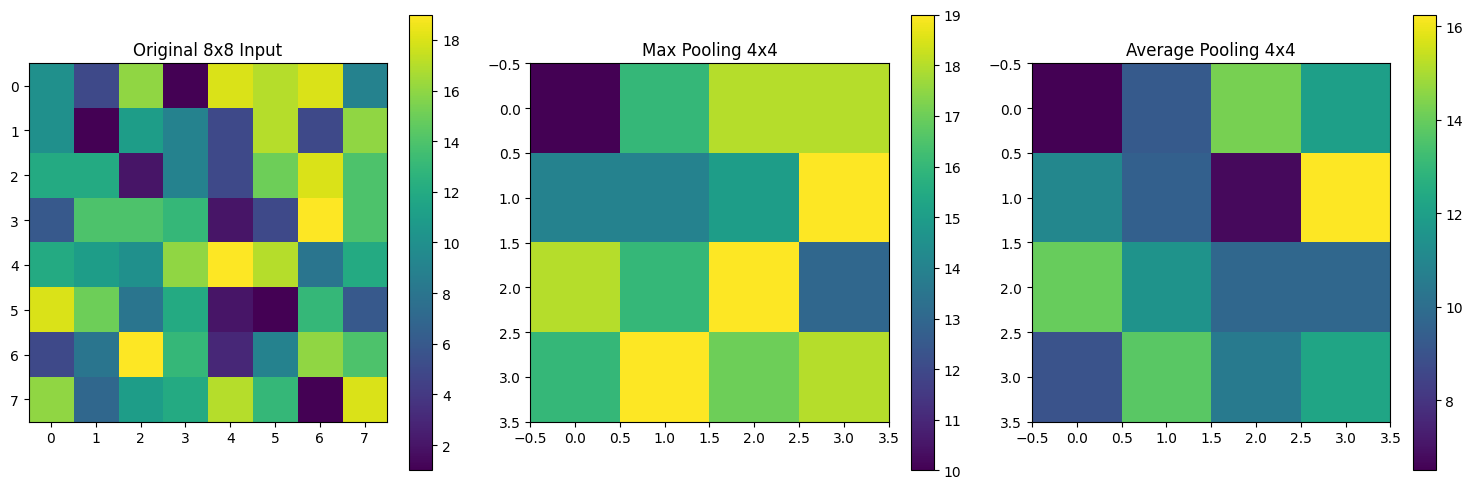


========== POOLING INFORMATION ==========
Learnable parameters in pooling layer = 0
Reason 1: Reduces spatial dimensions and computation.
Reason 2: Provides limited translation invariance.

========== PARAMETER COUNT COMPARISON ==========

Layer 1
Input: (28, 28, 1)
Output: (28, 28, 8)
Kernel: 3 x 3
Convolution parameters: 80
Fully connected parameters: 4,923,520
FC / Conv ratio: 61,544.00

Layer 2
Input: (28, 28, 8)
Output: (28, 28, 16)
Kernel: 3 x 3
Convolution parameters: 1,168
Fully connected parameters: 78,688,512
FC / Conv ratio: 67,370.30

Layer 3
Input: (224, 224, 3)
Output: (224, 224, 64)
Kernel: 3 x 3
Convolution parameters: 1,792
Fully connected parameters: 483,388,358,656
FC / Conv ratio: 269,747,968.00


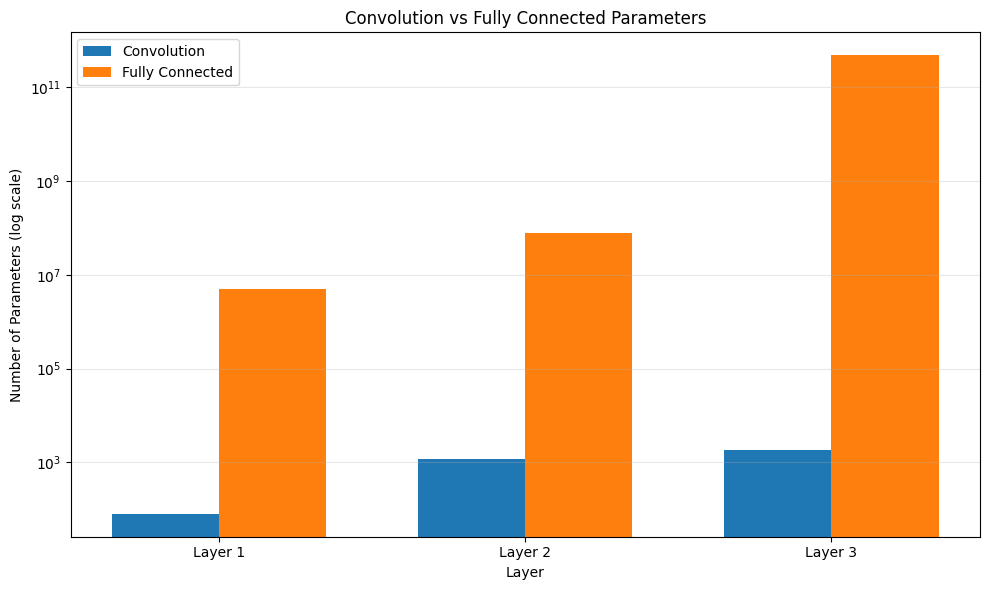

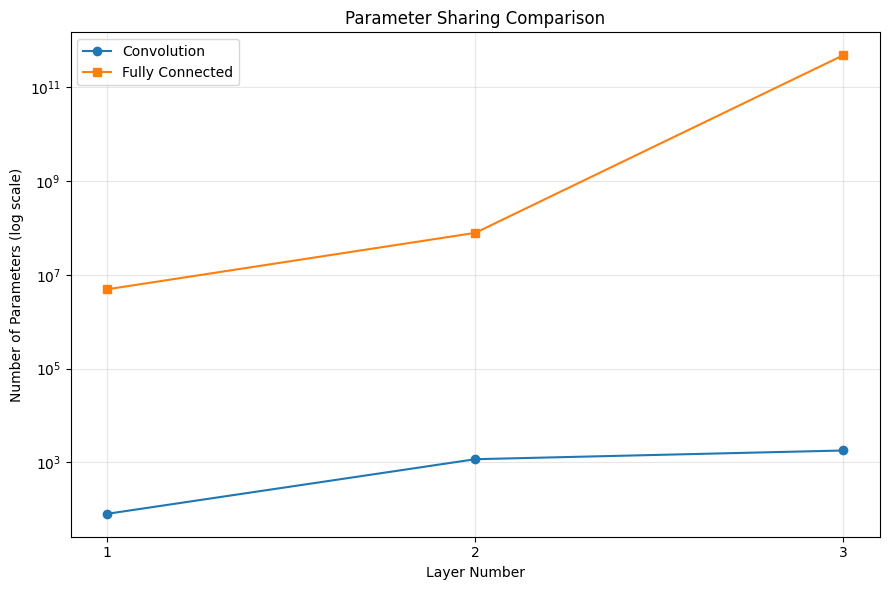


========== THIRD LAYER ==========
Input: 224 x 224 x 3
Output: 224 x 224 x 64
Kernel: 3 x 3
Convolution parameters: 1,792
Fully connected parameters: 483,388,358,656
FC / Conv ratio: 269,747,968.00
Convolution is necessary because a fully connected equivalent would require hundreds of billions of parameters.


In [6]:

# ================================================================
# DEEP LEARNING LAB 07
# TASK 2: DIMENSIONS, POOLING AND PARAMETER SHARING
# ================================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F


# ================================================================
# PART 1: CONVOLUTION FUNCTIONS
# ================================================================

def zero_pad(X, p):

    return np.pad(
        X,
        ((0, 0), (p, p), (p, p), (0, 0)),
        mode='constant'
    )


def conv_single_step(a_slice, W, b):

    return np.sum(a_slice * W) + float(np.squeeze(b))


def conv_forward(A_prev, W, b, stride=1, pad=0):

    m, n_H, n_W, n_C = A_prev.shape

    f, _, n_C_prev, n_C_out = W.shape

    assert n_C == n_C_prev

    out_H = int((n_H + 2 * pad - f) / stride) + 1
    out_W = int((n_W + 2 * pad - f) / stride) + 1

    Z = np.zeros((m, out_H, out_W, n_C_out))

    A_pad = zero_pad(A_prev, pad)

    for i in range(m):
        for h in range(out_H):
            for w in range(out_W):
                for c in range(n_C_out):

                    vert_start = h * stride
                    vert_end = vert_start + f

                    horiz_start = w * stride
                    horiz_end = horiz_start + f

                    a_slice = A_pad[
                        i,
                        vert_start:vert_end,
                        horiz_start:horiz_end,
                        :
                    ]

                    Z[i, h, w, c] = conv_single_step(
                        a_slice,
                        W[:, :, :, c],
                        b[:, :, :, c]
                    )

    cache = (A_prev, W, b, stride, pad)

    return Z, cache


# ================================================================
# PART 2: OUTPUT DIMENSION FORMULA
# ================================================================

def calculate_output_dimension(n_in, f, p, s):

    return int(np.floor((n_in + 2 * p - f) / s) + 1)


# Given table values
cases = [
    (28, 3, 1, 1),
    (28, 3, 0, 1),
    (28, 5, 2, 1),
    (28, 5, 0, 1),
    (28, 3, 1, 2),
    (32, 7, 3, 2)
]

print("\n========== OUTPUT DIMENSION TABLE ==========")

print("n_in\tf\tp\ts\tn_out")

for n_in, f, p, s in cases:

    n_out = calculate_output_dimension(n_in, f, p, s)

    print(n_in, "\t", f, "\t", p, "\t", s, "\t", n_out)


# ================================================================
# PART 3: VERIFY EVERY ROW USING conv_forward
# ================================================================

print("\n========== CONVOLUTION VERIFICATION ==========")

for index, (n_in, f, p, s) in enumerate(cases, start=1):

    # Create input image
    A_prev = np.random.randn(1, n_in, n_in, 1)

    # Create convolution filter
    W = np.random.randn(f, f, 1, 1)

    # Bias
    b = np.zeros((1, 1, 1, 1))

    # Apply convolution
    Z, cache = conv_forward(
        A_prev,
        W,
        b,
        stride=s,
        pad=p
    )

    # Calculate expected output
    expected = calculate_output_dimension(n_in, f, p, s)

    print(
        "Row", index,
        "| Expected:", expected,
        "| Actual:", Z.shape[1],
        "| Verified:", Z.shape[1] == expected
    )


# ================================================================
# PART 4: SAME CONVOLUTION
# ================================================================

print("\n========== SAME CONVOLUTION ==========")

print("Row 1: f=3, p=1, stride=1")

print("Row 3: f=5, p=2, stride=1")

print("General rule: p = (f-1)/2 for odd filters and stride 1")


# ================================================================
# PART 5: POOLING FORWARD FUNCTION
# ================================================================

def pool_forward(A_prev, f, stride=1, mode="max"):

    """
    A_prev shape: (m, n_H, n_W, n_C)

    Supports:
    1. max pooling
    2. average pooling
    """

    m, n_H, n_W, n_C = A_prev.shape

    out_H = int((n_H - f) / stride) + 1
    out_W = int((n_W - f) / stride) + 1

    A = np.zeros((m, out_H, out_W, n_C))

    for i in range(m):

        for h in range(out_H):

            for w in range(out_W):

                for c in range(n_C):

                    vert_start = h * stride
                    vert_end = vert_start + f

                    horiz_start = w * stride
                    horiz_end = horiz_start + f

                    # Extract input region
                    a_slice = A_prev[
                        i,
                        vert_start:vert_end,
                        horiz_start:horiz_end,
                        c
                    ]

                    if mode == "max":

                        A[i, h, w, c] = np.max(a_slice)

                    elif mode == "average":

                        A[i, h, w, c] = np.mean(a_slice)

                    else:

                        raise ValueError(
                            "Mode must be 'max' or 'average'"
                        )

    return A


# ================================================================
# PART 6: CREATE 8x8 INPUT
# ================================================================

np.random.seed(10)

X = np.random.randint(
    1, 20, size=(1, 8, 8, 1)
).astype(float)

print("\n========== 8x8 INPUT ==========")

print(X[0, :, :, 0])


# ================================================================
# PART 7: APPLY MAX AND AVERAGE POOLING
# ================================================================

max_output = pool_forward(
    X,
    f=2,
    stride=2,
    mode="max"
)

average_output = pool_forward(
    X,
    f=2,
    stride=2,
    mode="average"
)

print("\n========== MAX POOLING OUTPUT ==========")

print(max_output[0, :, :, 0])

print("\n========== AVERAGE POOLING OUTPUT ==========")

print(average_output[0, :, :, 0])


# ================================================================
# PART 8: VERIFY POOLING USING PYTORCH
# ================================================================

# Convert NHWC to NCHW
torch_X = torch.tensor(
    X.transpose(0, 3, 1, 2),
    dtype=torch.float64
)

# PyTorch max pooling
torch_max = F.max_pool2d(
    torch_X,
    kernel_size=2,
    stride=2
)

# PyTorch average pooling
torch_average = F.avg_pool2d(
    torch_X,
    kernel_size=2,
    stride=2
)

# Convert PyTorch output back to NHWC
torch_max = torch_max.numpy().transpose(0, 2, 3, 1)

torch_average = (
    torch_average.numpy().transpose(0, 2, 3, 1)
)

print("\n========== PYTORCH VERIFICATION ==========")

print(
    "Max pooling matches:",
    np.allclose(max_output, torch_max)
)

print(
    "Average pooling matches:",
    np.allclose(average_output, torch_average)
)


# ================================================================
# PART 9: DISPLAY INPUT AND POOLING OUTPUTS
# ================================================================

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)

plt.imshow(X[0, :, :, 0], cmap="viridis")

plt.title("Original 8x8 Input")

plt.colorbar()


plt.subplot(1, 3, 2)

plt.imshow(max_output[0, :, :, 0], cmap="viridis")

plt.title("Max Pooling 4x4")

plt.colorbar()


plt.subplot(1, 3, 3)

plt.imshow(average_output[0, :, :, 0], cmap="viridis")

plt.title("Average Pooling 4x4")

plt.colorbar()


plt.tight_layout()

plt.show()


# ================================================================
# PART 10: POOLING PARAMETERS AND USES
# ================================================================

print("\n========== POOLING INFORMATION ==========")

print("Learnable parameters in pooling layer = 0")

print("Reason 1: Reduces spatial dimensions and computation.")

print("Reason 2: Provides limited translation invariance.")


# ================================================================
# PART 11: PARAMETER SHARING
# ================================================================

# Parameter formula for convolution:
#
# (kernel height x kernel width x input channels x output channels)
# + output channels (biases)


def convolution_parameters(f, input_channels, output_channels):

    weights = f * f * input_channels * output_channels

    biases = output_channels

    return weights + biases


# Fully connected equivalent:
#
# Input neurons x Output neurons + output biases


def fully_connected_parameters(
    input_height,
    input_width,
    input_channels,
    output_height,
    output_width,
    output_channels
):

    input_neurons = (
        input_height * input_width * input_channels
    )

    output_neurons = (
        output_height * output_width * output_channels
    )

    weights = input_neurons * output_neurons

    biases = output_neurons

    return weights + biases


# ================================================================
# PART 12: CALCULATE THREE PARAMETER COUNTS
# ================================================================

layers = [
    {
        "input": (28, 28, 1),
        "output": (28, 28, 8),
        "kernel": 3
    },

    {
        "input": (28, 28, 8),
        "output": (28, 28, 16),
        "kernel": 3
    },

    {
        "input": (224, 224, 3),
        "output": (224, 224, 64),
        "kernel": 3
    }
]

conv_counts = []
fc_counts = []
ratios = []

print("\n========== PARAMETER COUNT COMPARISON ==========")

for i, layer in enumerate(layers, start=1):

    H_in, W_in, C_in = layer["input"]

    H_out, W_out, C_out = layer["output"]

    f = layer["kernel"]

    conv_params = convolution_parameters(
        f,
        C_in,
        C_out
    )

    fc_params = fully_connected_parameters(
        H_in,
        W_in,
        C_in,
        H_out,
        W_out,
        C_out
    )

    ratio = fc_params / conv_params

    conv_counts.append(conv_params)

    fc_counts.append(fc_params)

    ratios.append(ratio)

    print("\nLayer", i)

    print("Input:", layer["input"])

    print("Output:", layer["output"])

    print("Kernel:", f, "x", f)

    print("Convolution parameters:", f"{conv_params:,}")

    print("Fully connected parameters:", f"{fc_params:,}")

    print("FC / Conv ratio:", f"{ratio:,.2f}")


# ================================================================
# PART 13: PARAMETER COUNT BAR GRAPH
# ================================================================

x = np.arange(len(layers))

width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    conv_counts,
    width,
    label="Convolution"
)

plt.bar(
    x + width / 2,
    fc_counts,
    width,
    label="Fully Connected"
)

plt.yscale("log")

plt.xlabel("Layer")

plt.ylabel("Number of Parameters (log scale)")

plt.title("Convolution vs Fully Connected Parameters")

plt.xticks(
    x,
    ["Layer 1", "Layer 2", "Layer 3"]
)

plt.legend()

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()


# ================================================================
# PART 14: PARAMETER COUNT COMPARISON GRAPH
# ================================================================

plt.figure(figsize=(9, 6))

plt.plot(
    [1, 2, 3],
    conv_counts,
    marker="o",
    label="Convolution"
)

plt.plot(
    [1, 2, 3],
    fc_counts,
    marker="s",
    label="Fully Connected"
)

plt.yscale("log")

plt.xlabel("Layer Number")

plt.ylabel("Number of Parameters (log scale)")

plt.title("Parameter Sharing Comparison")

plt.xticks([1, 2, 3])

plt.legend()

plt.grid(True, which="both", alpha=0.3)

plt.tight_layout()

plt.show()


# ================================================================
# PART 15: THIRD LAYER EXPLANATION
# ================================================================

print("\n========== THIRD LAYER ==========")

print("Input: 224 x 224 x 3")

print("Output: 224 x 224 x 64")

print("Kernel: 3 x 3")

print("Convolution parameters:", f"{conv_counts[2]:,}")

print("Fully connected parameters:", f"{fc_counts[2]:,}")

print("FC / Conv ratio:", f"{ratios[2]:,.2f}")

print(
    "Convolution is necessary because a fully connected "
    "equivalent would require hundreds of billions of parameters."
)


# ================================================================
# END OF TASK 2
# ================================================================


========== NUMPY FORWARD PASS ==========
Input shape: (2, 5, 5, 2)
Filter shape: (3, 3, 2, 3)
Output shape: (2, 5, 5, 3)

dZ shape: (2, 5, 5, 3)

========== NUMPY BACKWARD PASS ==========
dA_prev shape: (2, 5, 5, 2)
dW shape: (3, 3, 2, 3)
db shape: (1, 1, 1, 3)

========== SHAPE VERIFICATION ==========
dA_prev shape verified: (2, 5, 5, 2)
dW shape verified: (3, 3, 2, 3)
db shape verified: (1, 1, 1, 3)
ALL GRADIENT SHAPES ARE CORRECT

========== RELATIVE DIFFERENCES ==========
Forward output difference: 7.301959527373466e-17
dA_prev difference: 9.179336681438069e-17
dW difference: 1.0698403989480056e-16
db difference: 6.821683960760693e-17

========== VERIFICATION RESULTS ==========
Forward verified: True
dA_prev verified: True
dW verified: True
db verified: True
SUCCESS: NUMPY AND PYTORCH MATCH


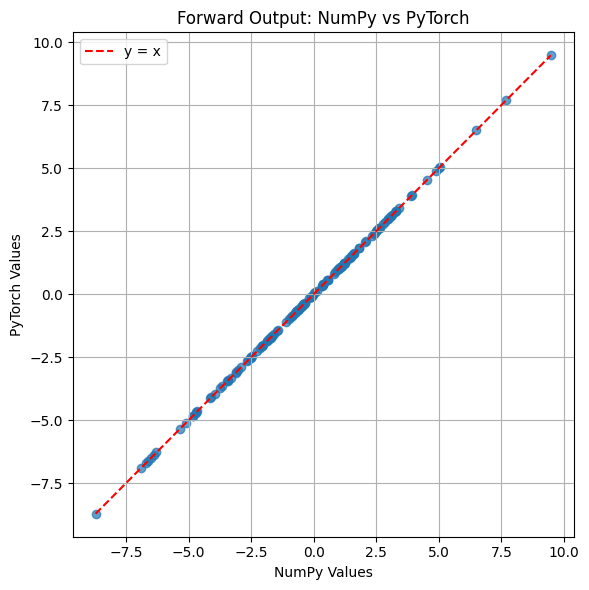

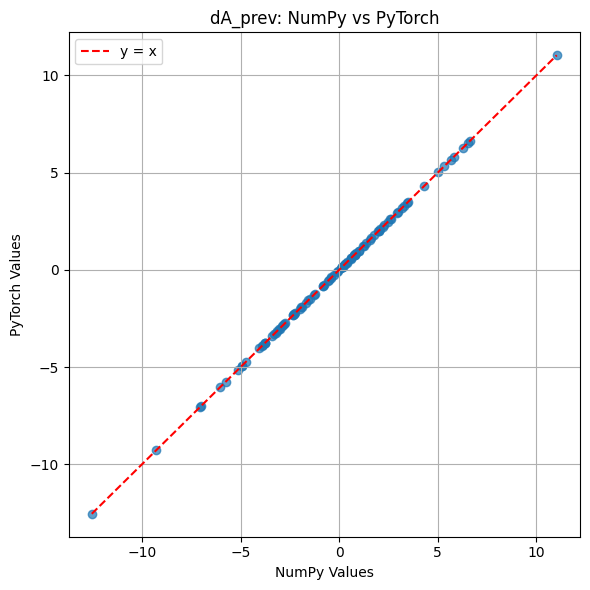

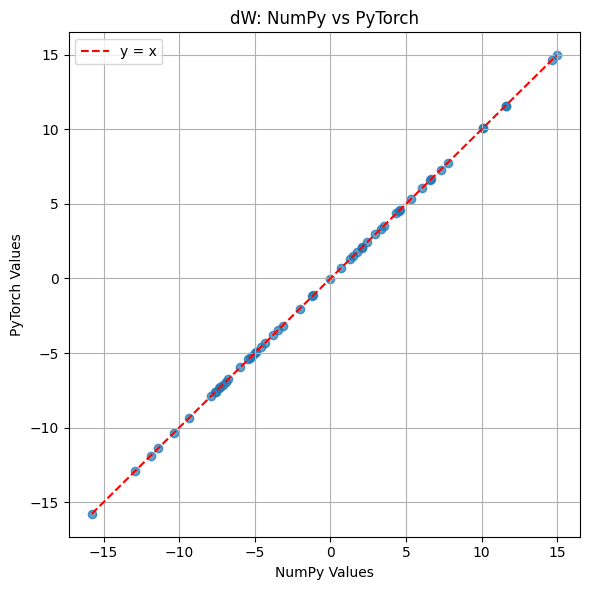

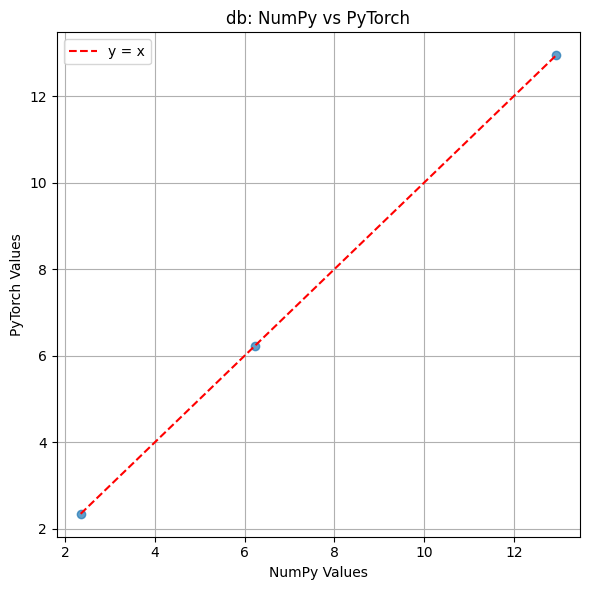


========== WRONG IMPLEMENTATION ==========
dA_prev wrong difference: 0.8588537220539174
dW wrong difference: 0.8804417609663299
db wrong difference: 0.9493772451494742

========== TASK 3 FINAL SUMMARY ==========
Correct forward difference: 7.301959527373466e-17
Correct dA difference: 9.179336681438069e-17
Correct dW difference: 1.0698403989480056e-16
Correct db difference: 6.821683960760693e-17

Wrong dA difference: 0.8588537220539174
Wrong dW difference: 0.8804417609663299
Wrong db difference: 0.9493772451494742

Verification threshold: 1e-10
Correct implementation uses += for all three gradients.
Task 3 completed.


In [7]:

# ================================================================
# DEEP LEARNING LAB 07
# TASK 3: THE BACKWARD PASS, VERIFIED
# ================================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

np.random.seed(3)
torch.manual_seed(3)


# ================================================================
# PART 1: ZERO PADDING
# ================================================================

def zero_pad(X, p):

    return np.pad(
        X,
        ((0, 0), (p, p), (p, p), (0, 0)),
        mode='constant'
    )


# ================================================================
# PART 2: FORWARD CONVOLUTION
# ================================================================

def conv_single_step(a_slice, W, b):

    return np.sum(a_slice * W) + float(np.squeeze(b))


def conv_forward(A_prev, W, b, stride=1, pad=0):

    m, n_H, n_W, n_C = A_prev.shape

    f, _, n_C_prev, n_C_out = W.shape

    assert n_C == n_C_prev

    out_H = int((n_H + 2 * pad - f) / stride) + 1

    out_W = int((n_W + 2 * pad - f) / stride) + 1

    Z = np.zeros(
        (m, out_H, out_W, n_C_out),
        dtype=np.float64
    )

    Ap = zero_pad(A_prev, pad)

    for i in range(m):

        for h in range(out_H):

            for w in range(out_W):

                for c in range(n_C_out):

                    vert_start = h * stride
                    vert_end = vert_start + f

                    horiz_start = w * stride
                    horiz_end = horiz_start + f

                    a_slice = Ap[
                        i,
                        vert_start:vert_end,
                        horiz_start:horiz_end,
                        :
                    ]

                    Z[i, h, w, c] = conv_single_step(
                        a_slice,
                        W[:, :, :, c],
                        b[:, :, :, c]
                    )

    cache = (A_prev, W, b, stride, pad)

    return Z, cache


# ================================================================
# PART 3: BACKWARD CONVOLUTION
# ================================================================

def conv_backward(dZ, cache):

    A_prev, W, b, stride, pad = cache

    # Input dimensions
    m, n_H, n_W, n_C = A_prev.shape

    # Filter dimensions
    f, _, n_C_prev, n_C_out = W.shape

    # Output dimensions
    _, out_H, out_W, _ = dZ.shape

    # Initialize gradients
    dA_prev = np.zeros_like(A_prev)

    dW = np.zeros_like(W)

    db = np.zeros_like(b)

    # Apply padding
    Ap = zero_pad(A_prev, pad)

    dAp = zero_pad(np.zeros_like(A_prev), pad)

    # Backward convolution
    for i in range(m):

        for h in range(out_H):

            for w in range(out_W):

                for c in range(n_C_out):

                    vert_start = h * stride
                    vert_end = vert_start + f

                    horiz_start = w * stride
                    horiz_end = horiz_start + f

                    # Extract input slice
                    a_slice = Ap[
                        i,
                        vert_start:vert_end,
                        horiz_start:horiz_end,
                        :
                    ]

                    # Gradient from current output
                    dz = dZ[i, h, w, c]

                    # ------------------------------------------------
                    # THREE IMPORTANT GRADIENT ACCUMULATIONS
                    # ------------------------------------------------

                    # 1. Gradient with respect to input
                    dAp[
                        i,
                        vert_start:vert_end,
                        horiz_start:horiz_end,
                        :
                    ] += W[:, :, :, c] * dz

                    # 2. Gradient with respect to filter weights
                    dW[:, :, :, c] += a_slice * dz

                    # 3. Gradient with respect to bias
                    db[:, :, :, c] += dz

    # Remove padding
    if pad == 0:

        dA_prev = dAp

    else:

        dA_prev = dAp[
            :,
            pad:-pad,
            pad:-pad,
            :
        ]

    return dA_prev, dW, db


# ================================================================
# PART 4: CREATE TEST INPUT AND FILTER
# ================================================================

m = 2

n_H = 5

n_W = 5

n_C = 2

n_C_out = 3

f = 3

stride = 1

pad = 1

# Input: NHWC
A_prev = np.random.randn(
    m, n_H, n_W, n_C
).astype(np.float64)

# Filter: HWIO
W = np.random.randn(
    f, f, n_C, n_C_out
).astype(np.float64)

# Bias
b = np.random.randn(
    1, 1, 1, n_C_out
).astype(np.float64)


# ================================================================
# PART 5: FORWARD PASS USING NUMPY
# ================================================================

Z, cache = conv_forward(
    A_prev,
    W,
    b,
    stride,
    pad
)

print("========== NUMPY FORWARD PASS ==========")

print("Input shape:", A_prev.shape)

print("Filter shape:", W.shape)

print("Output shape:", Z.shape)


# ================================================================
# PART 6: CREATE dZ
# ================================================================

dZ = np.random.randn(
    *Z.shape
).astype(np.float64)

print("\ndZ shape:", dZ.shape)


# ================================================================
# PART 7: BACKWARD PASS USING NUMPY
# ================================================================

dA_prev, dW, db = conv_backward(
    dZ,
    cache
)

print("\n========== NUMPY BACKWARD PASS ==========")

print("dA_prev shape:", dA_prev.shape)

print("dW shape:", dW.shape)

print("db shape:", db.shape)


# ================================================================
# PART 8: VERIFY GRADIENT SHAPES
# ================================================================

print("\n========== SHAPE VERIFICATION ==========")

assert dA_prev.shape == A_prev.shape

assert dW.shape == W.shape

assert db.shape == b.shape

print("dA_prev shape verified:", dA_prev.shape)

print("dW shape verified:", dW.shape)

print("db shape verified:", db.shape)

print("ALL GRADIENT SHAPES ARE CORRECT")


# ================================================================
# PART 9: PYTORCH FORWARD PASS
# ================================================================

# NHWC -> NCHW
torch_A = torch.tensor(
    A_prev.transpose(0, 3, 1, 2),
    dtype=torch.float64,
    requires_grad=True
)

# HWIO -> OIHW
torch_W = torch.tensor(
    W.transpose(3, 2, 0, 1),
    dtype=torch.float64,
    requires_grad=True
)

torch_b = torch.tensor(
    b.reshape(-1),
    dtype=torch.float64,
    requires_grad=True
)

# PyTorch convolution
torch_Z = F.conv2d(
    torch_A,
    torch_W,
    bias=torch_b,
    stride=stride,
    padding=pad
)

# NCHW -> NHWC
torch_Z_nhwc = (
    torch_Z.detach().numpy().transpose(0, 2, 3, 1)
)


# ================================================================
# PART 10: PYTORCH BACKWARD PASS
# ================================================================

# Convert dZ from NHWC to NCHW
torch_dZ = torch.tensor(
    dZ.transpose(0, 3, 1, 2),
    dtype=torch.float64
)

# Backward pass
torch_Z.backward(torch_dZ)

# Extract PyTorch gradients

# NCHW -> NHWC
torch_dA = (
    torch_A.grad.detach().numpy().transpose(0, 2, 3, 1)
)

# OIHW -> HWIO
torch_dW = (
    torch_W.grad.detach().numpy().transpose(2, 3, 1, 0)
)

torch_db = (
    torch_b.grad.detach().numpy().reshape(1, 1, 1, n_C_out)
)


# ================================================================
# PART 11: RELATIVE DIFFERENCE FUNCTION
# ================================================================

def relative_difference(a, b):

    numerator = np.linalg.norm(a - b)

    denominator = (
        np.linalg.norm(a) + np.linalg.norm(b) + 1e-8
    )

    return numerator / denominator


# ================================================================
# PART 12: COMPARE FOUR QUANTITIES
# ================================================================

forward_diff = relative_difference(
    Z,
    torch_Z_nhwc
)

dA_diff = relative_difference(
    dA_prev,
    torch_dA
)

dW_diff = relative_difference(
    dW,
    torch_dW
)

db_diff = relative_difference(
    db,
    torch_db
)


print("\n========== RELATIVE DIFFERENCES ==========")

print("Forward output difference:", forward_diff)

print("dA_prev difference:", dA_diff)

print("dW difference:", dW_diff)

print("db difference:", db_diff)


# ================================================================
# PART 13: VERIFICATION THRESHOLD
# ================================================================

threshold = 1e-10

print("\n========== VERIFICATION RESULTS ==========")

print(
    "Forward verified:",
    forward_diff < threshold
)

print(
    "dA_prev verified:",
    dA_diff < threshold
)

print(
    "dW verified:",
    dW_diff < threshold
)

print(
    "db verified:",
    db_diff < threshold
)

if all(
    x < threshold
    for x in [
        forward_diff,
        dA_diff,
        dW_diff,
        db_diff
    ]
):

    print("SUCCESS: NUMPY AND PYTORCH MATCH")

else:

    print("CHECK IMPLEMENTATION")


# ================================================================
# PART 14: PLOT NUMPY VALUES AGAINST PYTORCH VALUES
# ================================================================

def comparison_plot(numpy_values, torch_values, title):

    # Flatten arrays
    x = numpy_values.flatten()

    y = torch_values.flatten()

    # Plot
    plt.figure(figsize=(6, 6))

    plt.scatter(
        x,
        y,
        alpha=0.7
    )

    # y = x reference line
    minimum = min(x.min(), y.min())

    maximum = max(x.max(), y.max())

    plt.plot(
        [minimum, maximum],
        [minimum, maximum],
        'r--',
        label='y = x'
    )

    plt.xlabel("NumPy Values")

    plt.ylabel("PyTorch Values")

    plt.title(title)

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.show()


# Plot 1: Forward output
comparison_plot(
    Z,
    torch_Z_nhwc,
    "Forward Output: NumPy vs PyTorch"
)

# Plot 2: Input gradient
comparison_plot(
    dA_prev,
    torch_dA,
    "dA_prev: NumPy vs PyTorch"
)

# Plot 3: Weight gradient
comparison_plot(
    dW,
    torch_dW,
    "dW: NumPy vs PyTorch"
)

# Plot 4: Bias gradient
comparison_plot(
    db,
    torch_db,
    "db: NumPy vs PyTorch"
)


# ================================================================
# PART 15: DEMONSTRATE THE ERROR OF USING =
# ================================================================

def conv_backward_wrong(dZ, cache):

    A_prev, W, b, stride, pad = cache

    m, n_H, n_W, n_C = A_prev.shape

    f, _, n_C_prev, n_C_out = W.shape

    _, out_H, out_W, _ = dZ.shape

    dAp = zero_pad(
        np.zeros_like(A_prev),
        pad
    )

    dW = np.zeros_like(W)

    db = np.zeros_like(b)

    Ap = zero_pad(A_prev, pad)

    for i in range(m):

        for h in range(out_H):

            for w in range(out_W):

                for c in range(n_C_out):

                    vert_start = h * stride

                    vert_end = vert_start + f

                    horiz_start = w * stride

                    horiz_end = horiz_start + f

                    a_slice = Ap[
                        i,
                        vert_start:vert_end,
                        horiz_start:horiz_end,
                        :
                    ]

                    dz = dZ[i, h, w, c]

                    # WRONG: using = instead of +=
                    dAp[
                        i,
                        vert_start:vert_end,
                        horiz_start:horiz_end,
                        :
                    ] = W[:, :, :, c] * dz

                    # WRONG: using = instead of +=
                    dW[:, :, :, c] = a_slice * dz

                    # WRONG: using = instead of +=
                    db[:, :, :, c] = dz

    if pad == 0:

        dA_prev_wrong = dAp

    else:

        dA_prev_wrong = dAp[
            :,
            pad:-pad,
            pad:-pad,
            :
        ]

    return dA_prev_wrong, dW, db


# Calculate wrong gradients
wrong_dA, wrong_dW, wrong_db = conv_backward_wrong(
    dZ,
    cache
)


# Calculate wrong relative differences
wrong_dA_diff = relative_difference(
    wrong_dA,
    torch_dA
)

wrong_dW_diff = relative_difference(
    wrong_dW,
    torch_dW
)

wrong_db_diff = relative_difference(
    wrong_db,
    torch_db
)


print("\n========== WRONG IMPLEMENTATION ==========")

print("dA_prev wrong difference:", wrong_dA_diff)

print("dW wrong difference:", wrong_dW_diff)

print("db wrong difference:", wrong_db_diff)


# ================================================================
# PART 16: FINAL SUMMARY
# ================================================================

print("\n========== TASK 3 FINAL SUMMARY ==========")

print("Correct forward difference:", forward_diff)

print("Correct dA difference:", dA_diff)

print("Correct dW difference:", dW_diff)

print("Correct db difference:", db_diff)

print("\nWrong dA difference:", wrong_dA_diff)

print("Wrong dW difference:", wrong_dW_diff)

print("Wrong db difference:", wrong_db_diff)

print("\nVerification threshold:", threshold)

print("Correct implementation uses += for all three gradients.")

print("Task 3 completed.")


In [8]:
# ============================================================
# TASK 4: WHEN DOES CONVOLUTION ACTUALLY PAY?
# Dataset: Fashion-MNIST
# Framework: PyTorch
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
import time
import copy

# ------------------------------------------------------------
# 1. SETUP
# ------------------------------------------------------------

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

BATCH_SIZE = 128
LEARNING_RATE = 1e-3
EPOCHS = 12

# Load Fashion-MNIST
transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Convert images into NumPy arrays for translation experiment
X_train = train_data.data.numpy().astype(np.float32) / 255.0
y_train = train_data.targets.numpy().astype(np.int64)

X_test = test_data.data.numpy().astype(np.float32) / 255.0
y_test = test_data.targets.numpy().astype(np.int64)

print("\nTraining images:", X_train.shape)
print("Testing images:", X_test.shape)


# ------------------------------------------------------------
# 2. CNN MODEL
# ------------------------------------------------------------

class CNN(nn.Module):

    def __init__(self, c1=8, c2=16, h=32):

        super().__init__()

        self.feat = nn.Sequential(

            nn.Conv2d(1, c1, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(c1, c2, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.head = nn.Sequential(

            nn.Flatten(),

            nn.Linear(c2 * 7 * 7, h),
            nn.ReLU(),

            nn.Linear(h, 10)
        )

    def forward(self, x):

        return self.head(self.feat(x))


# ------------------------------------------------------------
# 3. FULLY CONNECTED NETWORK MODEL
# ------------------------------------------------------------

class FCN(nn.Module):

    def __init__(self, hidden):

        super().__init__()

        layers = [
            nn.Flatten(),
            nn.Linear(28 * 28, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 10)
        ]

        self.network = nn.Sequential(*layers)

    def forward(self, x):

        return self.network(x)


# ------------------------------------------------------------
# 4. PARAMETER COUNT FUNCTION
# ------------------------------------------------------------

def count_parameters(model):

    return sum(p.numel() for p in model.parameters()
               if p.requires_grad)


# ------------------------------------------------------------
# 5. TRAINING FUNCTION
# ------------------------------------------------------------

def train_model(model, X, y, epochs=12):

    model = model.to(device)

    X_tensor = torch.tensor(X, dtype=torch.float32).unsqueeze(1)
    y_tensor = torch.tensor(y, dtype=torch.long)

    dataset = TensorDataset(X_tensor, y_tensor)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    criterion = nn.CrossEntropyLoss()

    start_time = time.time()

    for epoch in range(epochs):

        model.train()
        total_loss = 0

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(loader)

        print(
            f"Epoch {epoch+1:02d}/{epochs} "
            f"| Loss: {avg_loss:.4f}"
        )

    elapsed = time.time() - start_time

    print(f"Training time: {elapsed:.1f} seconds")

    return model


# ------------------------------------------------------------
# 6. TEST ACCURACY FUNCTION
# ------------------------------------------------------------

def test_accuracy(model, X, y):

    model.eval()

    X_tensor = torch.tensor(
        X, dtype=torch.float32
    ).unsqueeze(1)

    y_tensor = torch.tensor(y, dtype=torch.long)

    dataset = TensorDataset(X_tensor, y_tensor)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total

    return accuracy


# ------------------------------------------------------------
# PART A - 1: MATCHED PARAMETER BUDGETS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PART A: CNN vs FULLY CONNECTED NETWORK")
print("=" * 60)


# Four CNN configurations
cnn_configs = [

    (4, 8, 32),
    (8, 16, 64),
    (12, 24, 128),
    (16, 32, 256)
]

# Five FCN configurations
fcn_configs = [16, 64, 128, 256, 512]


cnn_results = []
fcn_results = []

cnn_models = []
fcn_models = []


# ------------------------------------------------------------
# Train four CNNs
# ------------------------------------------------------------

print("\nTraining CNN models...")

for i, (c1, c2, h) in enumerate(cnn_configs):

    print(f"\nCNN Model {i+1}: c1={c1}, c2={c2}, h={h}")

    model = CNN(c1, c2, h)

    params = count_parameters(model)

    model = train_model(
        model,
        X_train,
        y_train,
        epochs=12
    )

    accuracy = test_accuracy(
        model,
        X_test,
        y_test
    )

    cnn_results.append((params, accuracy))
    cnn_models.append(model)

    print("Parameters:", params)
    print(f"Test Accuracy: {accuracy:.2f}%")


# ------------------------------------------------------------
# Train five FCNs
# ------------------------------------------------------------

print("\nTraining Fully Connected models...")

for i, hidden in enumerate(fcn_configs):

    print(f"\nFCN Model {i+1}: hidden={hidden}")

    model = FCN(hidden)

    params = count_parameters(model)

    model = train_model(
        model,
        X_train,
        y_train,
        epochs=12
    )

    accuracy = test_accuracy(
        model,
        X_test,
        y_test
    )

    fcn_results.append((params, accuracy))
    fcn_models.append(model)

    print("Parameters:", params)
    print(f"Test Accuracy: {accuracy:.2f}%")


# ------------------------------------------------------------
# Display Part A results
# ------------------------------------------------------------

print("\nCNN RESULTS")
print("-" * 45)

for i, (params, accuracy) in enumerate(cnn_results):

    print(
        f"CNN {i+1}: "
        f"Parameters = {params:,}, "
        f"Accuracy = {accuracy:.2f}%"
    )


print("\nFCN RESULTS")
print("-" * 45)

for i, (params, accuracy) in enumerate(fcn_results):

    print(
        f"FCN {i+1}: "
        f"Parameters = {params:,}, "
        f"Accuracy = {accuracy:.2f}%"
    )


# ------------------------------------------------------------
# PART A - 2: ACCURACY vs PARAMETER COUNT
# ------------------------------------------------------------

cnn_params = [x[0] for x in cnn_results]
cnn_acc = [x[1] for x in cnn_results]

fcn_params = [x[0] for x in fcn_results]
fcn_acc = [x[1] for x in fcn_results]

plt.figure(figsize=(9, 6))

plt.plot(
    cnn_params,
    cnn_acc,
    marker="o",
    linewidth=2,
    label="CNN"
)

plt.plot(
    fcn_params,
    fcn_acc,
    marker="s",
    linewidth=2,
    label="Fully Connected"
)

plt.xscale("log")

plt.xlabel("Number of Parameters (log scale)")
plt.ylabel("Test Accuracy (%)")

plt.title("CNN vs Fully Connected: Accuracy vs Parameters")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# PART A - 3: SMALLEST CNN MATCHING LARGEST FCN
# ------------------------------------------------------------

largest_fcn_accuracy = fcn_results[-1][1]
largest_fcn_params = fcn_results[-1][0]

print("\nLargest FCN accuracy:", round(largest_fcn_accuracy, 2), "%")
print("Largest FCN parameters:", f"{largest_fcn_params:,}")

matching_cnns = [

    (i, cnn_results[i][0], cnn_results[i][1])

    for i in range(len(cnn_results))

    if cnn_results[i][1] >= largest_fcn_accuracy
]

if matching_cnns:

    smallest_match = min(
        matching_cnns,
        key=lambda x: x[1]
    )

    index, small_cnn_params, small_cnn_accuracy = smallest_match

    ratio = largest_fcn_params / small_cnn_params

    print("\nSmallest CNN matching/beating largest FCN:")

    print("CNN model:", index + 1)
    print("CNN accuracy:", round(small_cnn_accuracy, 2), "%")
    print("CNN parameters:", f"{small_cnn_params:,}")

    print("Largest FCN parameters:", f"{largest_fcn_params:,}")

    print(
        "FCN/CNN parameter ratio:",
        round(ratio, 2),
        "times"
    )

else:

    print(
        "\nNo CNN matched the largest FCN accuracy "
        "within these configurations."
    )


# ------------------------------------------------------------
# PART A - 4: SHORTER TRAINING BUDGET (4 EPOCHS)
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SHORT TRAINING EXPERIMENT: 4 EPOCHS vs 12 EPOCHS")
print("=" * 60)

# Select the best CNN and best FCN from Part A
best_cnn_index = int(np.argmax(cnn_acc))
best_fcn_index = int(np.argmax(fcn_acc))

best_cnn_config = cnn_configs[best_cnn_index]
best_fcn_config = fcn_configs[best_fcn_index]

best_cnn_12_acc = cnn_results[best_cnn_index][1]
best_fcn_12_acc = fcn_results[best_fcn_index][1]

print("\nBest CNN configuration:", best_cnn_config)
print("Best FCN hidden size:", best_fcn_config)

# Train fresh CNN for only 4 epochs
short_cnn = CNN(*best_cnn_config)

short_cnn = train_model(
    short_cnn,
    X_train,
    y_train,
    epochs=4
)

short_cnn_acc = test_accuracy(
    short_cnn,
    X_test,
    y_test
)

# Train fresh FCN for only 4 epochs
short_fcn = FCN(best_fcn_config)

short_fcn = train_model(
    short_fcn,
    X_train,
    y_train,
    epochs=4
)

short_fcn_acc = test_accuracy(
    short_fcn,
    X_test,
    y_test
)

cnn_drop = best_cnn_12_acc - short_cnn_acc
fcn_drop = best_fcn_12_acc - short_fcn_acc

print("\nSHORT TRAINING RESULTS")
print("-" * 45)

print(f"Best CNN after 12 epochs: {best_cnn_12_acc:.2f}%")
print(f"Same CNN after 4 epochs:  {short_cnn_acc:.2f}%")
print(f"CNN accuracy drop:       {cnn_drop:.2f} percentage points")

print()

print(f"Best FCN after 12 epochs: {best_fcn_12_acc:.2f}%")
print(f"Same FCN after 4 epochs:  {short_fcn_acc:.2f}%")
print(f"FCN accuracy drop:       {fcn_drop:.2f} percentage points")

if cnn_drop > fcn_drop:

    print("\nCNN was hurt more by the shorter training budget.")

elif fcn_drop > cnn_drop:

    print("\nFully Connected network was hurt more by the shorter budget.")

else:

    print("\nBoth families had approximately the same accuracy drop.")


# ------------------------------------------------------------
# PART B: TRANSLATION EXPERIMENT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PART B: TRANSLATION EXPERIMENT")
print("=" * 60)


# ------------------------------------------------------------
# 1. SHIFT IMAGES FUNCTION
# ------------------------------------------------------------

def shift_images(X, max_shift, seed):

    """Zero-filled random translation, by slicing a padded copy."""

    if max_shift == 0:
        return X.copy()

    r = np.random.RandomState(seed)

    m, H, W = X.shape

    P = np.pad(
        X,
        ((0, 0), (max_shift, max_shift), (max_shift, max_shift))
    )

    dy = r.randint(0, 2 * max_shift + 1, m)
    dx = r.randint(0, 2 * max_shift + 1, m)

    out = np.empty_like(X)

    for i in range(m):

        out[i] = P[
            i,
            dy[i]:dy[i] + H,
            dx[i]:dx[i] + W
        ]

    return out


# ------------------------------------------------------------
# 2. SELECT BEST MODELS FROM PART A
# ------------------------------------------------------------

best_cnn = copy.deepcopy(
    CNN(*best_cnn_config)
)

best_fcn = copy.deepcopy(
    FCN(best_fcn_config)
)

print("Best CNN configuration:", best_cnn_config)
print("Best FCN hidden size:", best_fcn_config)


# ------------------------------------------------------------
# 3. TRAIN BOTH MODELS AT EACH TRANSLATION LEVEL
# ------------------------------------------------------------

translation_levels = [0, 1, 2, 3, 4, 5]

cnn_translation_acc = []
fcn_translation_acc = []

for shift in translation_levels:

    print("\n" + "-" * 50)
    print(f"TRANSLATION = {shift} PIXELS")
    print("-" * 50)

    # Apply same translation level to training and test sets
    X_train_shifted = shift_images(
        X_train,
        shift,
        seed=100 + shift
    )

    X_test_shifted = shift_images(
        X_test,
        shift,
        seed=200 + shift
    )

    # Train CNN from scratch
    print("\nTraining CNN...")

    cnn_model = CNN(*best_cnn_config)

    cnn_model = train_model(
        cnn_model,
        X_train_shifted,
        y_train,
        epochs=12
    )

    cnn_accuracy = test_accuracy(
        cnn_model,
        X_test_shifted,
        y_test
    )

    # Train FCN from scratch
    print("\nTraining Fully Connected Network...")

    fcn_model = FCN(best_fcn_config)

    fcn_model = train_model(
        fcn_model,
        X_train_shifted,
        y_train,
        epochs=12
    )

    fcn_accuracy = test_accuracy(
        fcn_model,
        X_test_shifted,
        y_test
    )

    cnn_translation_acc.append(cnn_accuracy)
    fcn_translation_acc.append(fcn_accuracy)

    print("\nTranslation:", shift, "pixels")
    print(f"CNN Accuracy: {cnn_accuracy:.2f}%")
    print(f"FCN Accuracy: {fcn_accuracy:.2f}%")


# ------------------------------------------------------------
# PART B - 4: PLOT ACCURACY AGAINST TRANSLATION
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    translation_levels,
    cnn_translation_acc,
    marker="o",
    linewidth=2,
    label="CNN"
)

plt.plot(
    translation_levels,
    fcn_translation_acc,
    marker="s",
    linewidth=2,
    label="Fully Connected"
)

plt.xlabel("Maximum Translation (pixels)")
plt.ylabel("Test Accuracy (%)")

plt.title("Effect of Image Translation on Accuracy")

plt.xticks(translation_levels)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# PART B - 5: CNN ADVANTAGE
# ------------------------------------------------------------

cnn_advantage = [

    cnn_translation_acc[i] - fcn_translation_acc[i]

    for i in range(len(translation_levels))
]

plt.figure(figsize=(9, 5))

plt.plot(
    translation_levels,
    cnn_advantage,
    marker="o",
    linewidth=2
)

plt.axhline(0, linestyle="--")

plt.xlabel("Maximum Translation (pixels)")
plt.ylabel("CNN Advantage (percentage points)")

plt.title("CNN Advantage over Fully Connected Network")

plt.xticks(translation_levels)
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. REPORT CNN ADVANTAGE AND CHANGE FACTOR
# ------------------------------------------------------------

print("\nCNN ADVANTAGE RESULTS")
print("-" * 45)

for shift, advantage in zip(
    translation_levels,
    cnn_advantage
):

    print(
        f"Shift {shift}: "
        f"CNN advantage = {advantage:.2f} percentage points"
    )


advantage_0 = cnn_advantage[0]
advantage_5 = cnn_advantage[-1]

print("\nAdvantage at 0 pixels:", round(advantage_0, 2), "percentage points")
print("Advantage at 5 pixels:", round(advantage_5, 2), "percentage points")

if abs(advantage_0) > 1e-8:

    factor = abs(advantage_5 / advantage_0)

    print("Absolute change factor:", round(factor, 2), "times")

else:

    print("Factor cannot be calculated because advantage at 0 is zero.")

if advantage_5 > advantage_0:

    print("CNN advantage increased as translation grew.")

elif advantage_5 < advantage_0:

    print("CNN advantage decreased as translation grew.")

else:

    print("CNN advantage remained unchanged.")


# ------------------------------------------------------------
# 7. FINAL AUTOMATIC SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL SUMMARY")
print("=" * 60)

print(
    f"At 0-pixel shift: CNN={cnn_translation_acc[0]:.2f}%, "
    f"FCN={fcn_translation_acc[0]:.2f}%"
)

print(
    f"At 5-pixel shift: CNN={cnn_translation_acc[-1]:.2f}%, "
    f"FCN={fcn_translation_acc[-1]:.2f}%"
)

print(
    "\nRemember: CNN advantage = CNN accuracy - FCN accuracy."
)

print(
    "A positive value means CNN performs better; "
    "a negative value means FCN performs better."
)

Device: cpu

Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)

PART A: CNN vs FULLY CONNECTED NETWORK

Training CNN models...

CNN Model 1: c1=4, c2=8, h=32
Epoch 01/12 | Loss: 0.8409
Epoch 02/12 | Loss: 0.5530
Epoch 03/12 | Loss: 0.4813
Epoch 04/12 | Loss: 0.4298
Epoch 05/12 | Loss: 0.4036
Epoch 06/12 | Loss: 0.3787
Epoch 07/12 | Loss: 0.3642
Epoch 08/12 | Loss: 0.3500
Epoch 09/12 | Loss: 0.3388
Epoch 10/12 | Loss: 0.3281
Epoch 11/12 | Loss: 0.3204
Epoch 12/12 | Loss: 0.3113
Training time: 119.4 seconds
Parameters: 13242
Test Accuracy: 87.65%

CNN Model 2: c1=8, c2=16, h=64
Epoch 01/12 | Loss: 0.6835
Epoch 02/12 | Loss: 0.4354
Epoch 03/12 | Loss: 0.3862
Epoch 04/12 | Loss: 0.3549
Epoch 05/12 | Loss: 0.3336
Epoch 06/12 | Loss: 0.3123
Epoch 07/12 | Loss: 0.2986
Epoch 08/12 | Loss: 0.2841
Epoch 09/12 | Loss: 0.2704
Epoch 10/12 | Loss: 0.2586
Epoch 11/12 | Loss: 0.2497
Epoch 12/12 | Loss: 0.2396
Training time: 185.2 seconds
Parameters: 52138
Test Accuracy: 89.70%

CNN Mode

KeyboardInterrupt: 

In [ ]:
# ============================================================
# TASK 6: ARCHITECTURE ABLATION
# Requires X_train, y_train, X_test, y_test and device
# ============================================================

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd
from torch.utils.data import TensorDataset, DataLoader


# ------------------------------------------------------------
# 1. GENERAL CONFIGURATION
# ------------------------------------------------------------

BATCH_SIZE = 128
LEARNING_RATE = 1e-3
EPOCHS = 12


# ------------------------------------------------------------
# 2. ARCHITECTURE MODEL
# ------------------------------------------------------------

class AblationCNN(nn.Module):

    def __init__(
        self,
        variant="Reference",
        c1=8,
        c2=16,
        h=32
    ):

        super().__init__()

        # Reference: 2 convolution blocks, 3x3 kernels, pooling
        if variant == "Reference":

            self.feat = nn.Sequential(
                nn.Conv2d(1, c1, 3, padding=1),
                nn.ReLU(),
                nn.MaxPool2d(2),

                nn.Conv2d(c1, c2, 3, padding=1),
                nn.ReLU(),
                nn.MaxPool2d(2)
            )

            flattened_size = c2 * 7 * 7


        # Shallower: only 1 convolution block
        elif variant == "Shallower":

            self.feat = nn.Sequential(
                nn.Conv2d(1, c1, 3, padding=1),
                nn.ReLU(),
                nn.MaxPool2d(2)
            )

            flattened_size = c1 * 14 * 14


        # Deeper: 3 convolution blocks
        elif variant == "Deeper":

            c3 = 32

            self.feat = nn.Sequential(
                nn.Conv2d(1, c1, 3, padding=1),
                nn.ReLU(),
                nn.MaxPool2d(2),

                nn.Conv2d(c1, c2, 3, padding=1),
                nn.ReLU(),
                nn.MaxPool2d(2),

                nn.Conv2d(c2, c3, 3, padding=1),
                nn.ReLU(),
                nn.MaxPool2d(2)
            )

            # 28 -> 14 -> 7 -> 3
            flattened_size = c3 * 3 * 3


        # No pooling: remove both pooling layers
        elif variant == "No pooling":

            self.feat = nn.Sequential(
                nn.Conv2d(1, c1, 3, padding=1),
                nn.ReLU(),

                nn.Conv2d(c1, c2, 3, padding=1),
                nn.ReLU()
            )

            flattened_size = c2 * 28 * 28


        # Wider kernel: 5x5 instead of 3x3
        elif variant == "Wider kernel":

            self.feat = nn.Sequential(
                nn.Conv2d(1, c1, 5, padding=2),
                nn.ReLU(),
                nn.MaxPool2d(2),

                nn.Conv2d(c1, c2, 5, padding=2),
                nn.ReLU(),
                nn.MaxPool2d(2)
            )

            flattened_size = c2 * 7 * 7


        # Widest kernel: 7x7 instead of 3x3
        elif variant == "Widest kernel":

            self.feat = nn.Sequential(
                nn.Conv2d(1, c1, 7, padding=3),
                nn.ReLU(),
                nn.MaxPool2d(2),

                nn.Conv2d(c1, c2, 7, padding=3),
                nn.ReLU(),
                nn.MaxPool2d(2)
            )

            flattened_size = c2 * 7 * 7


        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flattened_size, h),
            nn.ReLU(),
            nn.Linear(h, 10)
        )


    def forward(self, x):

        x = self.feat(x)

        return self.head(x)


# ------------------------------------------------------------
# 3. PARAMETER COUNT
# ------------------------------------------------------------

def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


# ------------------------------------------------------------
# 4. TRAIN AND TEST FUNCTION WITH TIME
# ------------------------------------------------------------

def train_and_evaluate(model, X_train, y_train, X_test, y_test):

    model = model.to(device)

    Xtr = torch.tensor(
        X_train,
        dtype=torch.float32
    ).unsqueeze(1)

    Ytr = torch.tensor(
        y_train,
        dtype=torch.long
    )

    Xte = torch.tensor(
        X_test,
        dtype=torch.float32
    ).unsqueeze(1)

    Yte = torch.tensor(
        y_test,
        dtype=torch.long
    )

    train_loader = DataLoader(
        TensorDataset(Xtr, Ytr),
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0
    )

    test_loader = DataLoader(
        TensorDataset(Xte, Yte),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    criterion = nn.CrossEntropyLoss()

    # Start timing
    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.time()

    # Training
    for epoch in range(EPOCHS):

        model.train()

        total_loss = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{EPOCHS} "
            f"Loss: {total_loss / len(train_loader):.4f}"
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_time = time.time() - start_time

    # Testing
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total

    return accuracy, training_time


# ------------------------------------------------------------
# 5. DEFINE SIX ARCHITECTURES
# ------------------------------------------------------------

variants = [
    "Reference",
    "Shallower",
    "Deeper",
    "No pooling",
    "Wider kernel",
    "Widest kernel"
]

results = []

trained_ablation_models = {}


# ------------------------------------------------------------
# 6. TRAIN ALL SIX MODELS
# ------------------------------------------------------------

for variant in variants:

    print("\n" + "=" * 60)
    print("TRAINING:", variant)
    print("=" * 60)

    model = AblationCNN(variant=variant)

    params = count_parameters(model)

    print("Parameter count:", f"{params:,}")

    accuracy, training_time = train_and_evaluate(
        model,
        X_train,
        y_train,
        X_test,
        y_test
    )

    results.append({
        "Architecture": variant,
        "Parameters": params,
        "Accuracy": accuracy,
        "Training Time (seconds)": training_time
    })

    trained_ablation_models[variant] = model

    print("\nResults:")
    print("Parameters:", f"{params:,}")
    print(f"Test accuracy: {accuracy:.2f}%")
    print(f"Training time: {training_time:.2f} seconds")


# ------------------------------------------------------------
# 7. DISPLAY RESULTS TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\nFINAL ARCHITECTURE ABLATION RESULTS")

print(
    results_df.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.2f}%".format,
            "Training Time (seconds)": "{:.2f}".format
        }
    )
)


# ------------------------------------------------------------
# 8. PLOT ACCURACY BAR CHART
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(
    results_df["Architecture"],
    results_df["Accuracy"]
)

axes[0].set_title("Test Accuracy of Different Architectures")
axes[0].set_xlabel("Architecture")
axes[0].set_ylabel("Test Accuracy (%)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(axis="y")


# ------------------------------------------------------------
# 9. ACCURACY AGAINST PARAMETER COUNT
# ------------------------------------------------------------

axes[1].scatter(
    results_df["Parameters"],
    results_df["Accuracy"],
    s=80
)

for _, row in results_df.iterrows():

    axes[1].annotate(
        row["Architecture"],
        (row["Parameters"], row["Accuracy"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

axes[1].set_xscale("log")

axes[1].set_title("Accuracy vs Parameter Count")
axes[1].set_xlabel("Number of Parameters (log scale)")
axes[1].set_ylabel("Test Accuracy (%)")
axes[1].grid(True)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. FIND EXTRA PARAMETERS IN NO-POOLING MODEL
# ------------------------------------------------------------

reference_model = AblationCNN("Reference")
no_pool_model = AblationCNN("No pooling")

reference_params = count_parameters(reference_model)
no_pool_params = count_parameters(no_pool_model)

print("\nNO-POOLING PARAMETER COMPARISON")
print("-" * 45)

print("Reference parameters:", f"{reference_params:,}")
print("No-pooling parameters:", f"{no_pool_params:,}")

print(
    "No-pooling / Reference ratio:",
    round(no_pool_params / reference_params, 2),
    "times"
)

# Print parameter count of each layer
print("\nNo-pooling model layer parameters:")

for name, parameter in no_pool_model.named_parameters():

    print(
        f"{name:25s}",
        f"{parameter.numel():,}"
    )


# ------------------------------------------------------------
# 11. COMPARE TWO 3x3 CONVOLUTIONS WITH ONE 5x5
# ------------------------------------------------------------

# Use 16 input and 16 output channels.
# Two 3x3 convolutions: 16 -> 16 -> 16
two_3x3_parameters = (
    (3 * 3 * 16 * 16 + 16) +
    (3 * 3 * 16 * 16 + 16)
)

# One 5x5 convolution: 16 -> 16
one_5x5_parameters = (
    5 * 5 * 16 * 16 + 16
)

print("\nRECEPTIVE FIELD AND PARAMETER COMPARISON")
print("-" * 45)

print("Two 3x3 convolution parameters:", two_3x3_parameters)
print("One 5x5 convolution parameters:", one_5x5_parameters)

print(
    "Two 3x3 / One 5x5 ratio:",
    round(two_3x3_parameters / one_5x5_parameters, 3)
)

print("\nReceptive field of two 3x3 layers = 5x5")
print("Receptive field of one 5x5 layer = 5x5")


# ------------------------------------------------------------
# 12. RECOMMEND ARCHITECTURE BASED ON ACCURACY AND COST
# ------------------------------------------------------------

best_accuracy = results_df["Accuracy"].max()

# Models within 0.5 percentage points of the best accuracy
near_best = results_df[
    results_df["Accuracy"] >= best_accuracy - 0.5
]

# Among these, choose the model with fewer parameters
recommended = near_best.sort_values(
    by=["Parameters", "Training Time (seconds)"]
).iloc[0]

print("\nRECOMMENDED ARCHITECTURE")
print("-" * 45)

print("Architecture:", recommended["Architecture"])
print("Parameters:", f"{int(recommended['Parameters']):,}")
print(f"Accuracy: {recommended['Accuracy']:.2f}%")
print(
    f"Training time: "
    f"{recommended['Training Time (seconds)']:.2f} seconds"
)

print(
    "\nRecommendation rule: choose the smallest model "
    "whose accuracy is within 0.5 percentage points "
    "of the best result."
)

print("\nTASK 6 COMPLETED")


TRAINING: Reference
Parameter count: 26,698
Epoch 1/12 Loss: 0.7669
Epoch 2/12 Loss: 0.4367
Epoch 3/12 Loss: 0.3898
Epoch 4/12 Loss: 0.3623
Epoch 5/12 Loss: 0.3423
Epoch 6/12 Loss: 0.3252
Epoch 7/12 Loss: 0.3154
Epoch 8/12 Loss: 0.3027
Epoch 9/12 Loss: 0.2967
Epoch 10/12 Loss: 0.2883
Epoch 11/12 Loss: 0.2786
Epoch 12/12 Loss: 0.2704

Results:
Parameters: 26,698
Test accuracy: 88.92%
Training time: 177.39 seconds

TRAINING: Shallower
Parameter count: 50,618
Epoch 1/12 Loss: 0.6278
Epoch 2/12 Loss: 0.3744
Epoch 3/12 Loss: 0.3330
Epoch 4/12 Loss: 0.3098
Epoch 5/12 Loss: 0.2943
Epoch 6/12 Loss: 0.2797
Epoch 7/12 Loss: 0.2704
Epoch 8/12 Loss: 0.2602
Epoch 9/12 Loss: 0.2529
Epoch 10/12 Loss: 0.2469
Epoch 11/12 Loss: 0.2373
Epoch 12/12 Loss: 0.2316

Results:
Parameters: 50,618
Test accuracy: 89.64%
Training time: 110.58 seconds

TRAINING: Deeper
Parameter count: 15,466
Epoch 1/12 Loss: 0.8559
Epoch 2/12 Loss: 0.5254
Epoch 3/12 Loss: 0.4513
Epoch 4/12 Loss: 0.4071
Epoch 5/12 Loss: 0.3795
Epoc